# Khám phá dữ liệu sinh viên — Student Dropout
## 1. Đọc dữ liệu và kiểm tra cấu trúc ban đầu

### Mục đích
Đọc dữ liệu CSV, xác định kích thước và quan sát một số bản ghi đầu tiên.

### Cách thực hiện và lý do
- Dùng đường dẫn dựa trên thư mục dự án để thuận tiện chạy trên máy thành viên.
- Dùng dấu phân cách `;` theo định dạng file dữ liệu.
- Hiển thị 5 dòng đầu để kiểm tra các cột đã được tách đúng.

In [13]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
import pandas as pd

# Tìm thư mục dự án khi chạy từ thư mục gốc hoặc notebooks
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_path = project_dir / "data" / "raw" / "student_dropout.csv"

df = pd.read_csv(data_path, sep=";")

print("Số dòng, số cột:", df.shape)
display(df.head())

Số dòng, số cột: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### Nhận xét
- Đã đọc thành công dữ liệu gồm 4.424 dòng và 37 cột.
- Trong đó có 36 đặc trưng đầu vào và một biến mục tiêu `Target`.
- Các cột được tách riêng, cho thấy dấu phân cách đang sử dụng phù hợp.
- Chưa thay đổi hoặc loại bỏ bản ghi ở bước này.

## 2. Kiểm tra chất lượng dữ liệu và phân bố biến mục tiêu

### Mục đích
Kiểm tra kiểu dữ liệu, giá trị thiếu, dòng trùng và số lượng mẫu của từng lớp.

### Cách thực hiện và lý do
- `info()`: kiểm tra kiểu dữ liệu và số giá trị khác null.
- `isna()`: xác định có cần xử lý giá trị thiếu hay không.
- `duplicated()`: phát hiện các dòng trùng hoàn toàn.
- `value_counts()`: xác định phân bố ba lớp của biến mục tiêu.

Lưu ý: Một thuộc tính có kiểu số vẫn có thể biểu diễn mã danh mục,
chẳng hạn mã ngành học. Cần xem ý nghĩa biến trước khi chọn cách encoding.

In [20]:
# 1. Kiểm tra tên cột và kiểu dữ liệu
print("=== THÔNG TIN DỮ LIỆU ===")
df.info()

# 2. Kiểm tra giá trị thiếu
print("\n=== GIÁ TRỊ THIẾU ===")
missing = df.isna().sum()
print(missing[missing > 0])
print("Tổng giá trị thiếu:", missing.sum())

# 3. Kiểm tra dòng trùng hoàn toàn
print("\n=== DÒNG TRÙNG ===")
print("Số dòng trùng:", df.duplicated().sum())

# 4. Kiểm tra số lượng và tỷ lệ của từng lớp
print("\n=== PHÂN BỐ TARGET ===")
target_summary = pd.DataFrame({
    "Số lượng": df["Target"].value_counts(),
    "Tỷ lệ (%)": df["Target"].value_counts(normalize=True).mul(100).round(2)
})
display(target_summary)

=== THÔNG TIN DỮ LIỆU ===
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification    

,Số lượng,Tỷ lệ (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


### 2.1. Tổng hợp kết quả kiểm tra

Output của bước trước bị thu gọn do dài. Cell dưới đây hiển thị lại
các thông tin chính để thuận tiện kiểm chứng và ghi vào báo cáo.
Đây là bước tổng hợp, không thực hiện thêm thao tác xử lý dữ liệu.

In [21]:
print("Số mẫu:", len(df))
print("Số đặc trưng:", df.drop(columns="Target").shape[1])
print("Tổng giá trị thiếu:", df.isna().sum().sum())
print("Số dòng trùng:", df.duplicated().sum())
print("Các nhãn:", df["Target"].unique())

Số mẫu: 4424
Số đặc trưng: 36
Tổng giá trị thiếu: 0
Số dòng trùng: 0
Các nhãn: <StringArray>
['Dropout', 'Graduate', 'Enrolled']
Length: 3, dtype: str


### Nhận xét và quyết định xử lý

- Dataset có 4.424 mẫu, 36 đặc trưng và một biến mục tiêu.
- Không phát hiện giá trị thiếu bằng `isna()`, nên hiện chưa cần điền thiếu.
- Không phát hiện dòng trùng hoàn toàn, nên chưa cần loại dòng trùng.
- Biến mục tiêu có ba lớp:

| Lớp | Số lượng | Tỷ lệ |
|---|---:|---:|
| Graduate | 2.209 | 49,93% |
| Dropout | 1.421 | 32,12% |
| Enrolled | 794 | 17,95% |

- Số mẫu giữa các lớp chênh lệch; Graduate nhiều nhất, Enrolled ít nhất.
- Khi chia dữ liệu, nhóm dự kiến giữ tỷ lệ lớp bằng stratification.
- Khi đánh giá mô hình, nhóm dự kiến sử dụng Macro-F1 cùng các độ đo
  theo từng lớp, không chỉ dựa vào Accuracy.
- Kết quả kiểm tra này chưa chứng minh dữ liệu không có ngoại lệ,
  mã không hợp lệ hoặc vấn đề khác; các nội dung đó cần kiểm tra tiếp.

## 3. Trực quan hóa phân bố biến mục tiêu

### Mục đích
So sánh số lượng sinh viên thuộc ba lớp Dropout, Enrolled và Graduate.

### Lý do chọn biểu đồ
Biểu đồ cột phù hợp để so sánh số lượng giữa các nhóm danh mục.
Hiển thị thêm tỷ lệ phần trăm giúp nhận biết mức độ chênh lệch giữa các lớp.

### Đầu ra
Lưu biểu đồ vào `report/figures/01_target_distribution.png`
để sử dụng trong báo cáo và slide.

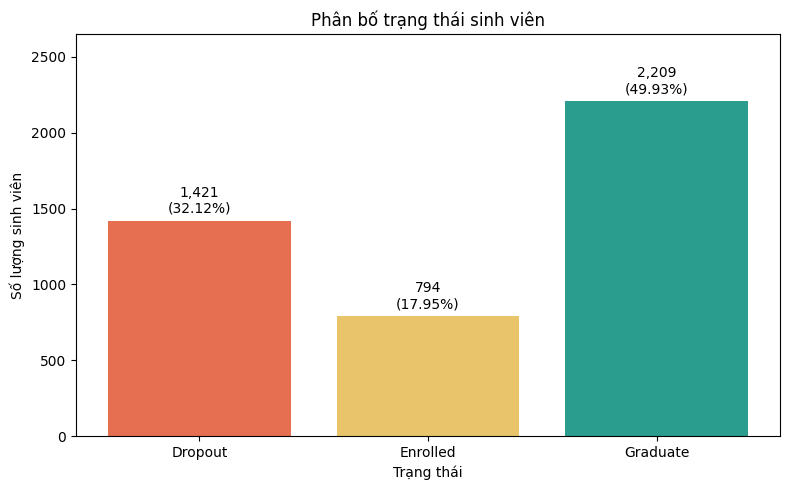

Đã lưu hình tại: c:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\report\figures\01_target_distribution.png


In [22]:
import matplotlib.pyplot as plt

# Tạo thư mục lưu hình
figure_dir = project_dir / "report" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# Cố định thứ tự lớp để dùng thống nhất trong các biểu đồ
class_order = ["Dropout", "Enrolled", "Graduate"]
counts = df["Target"].value_counts().reindex(class_order, fill_value=0)
percentages = counts / len(df) * 100

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    counts.index,
    counts.values,
    color=["#E76F51", "#E9C46A", "#2A9D8F"]
)

for bar, count, percentage in zip(bars, counts, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Phân bố trạng thái sinh viên")
ax.set_xlabel("Trạng thái")
ax.set_ylabel("Số lượng sinh viên")
ax.set_ylim(0, counts.max() * 1.2)

fig.tight_layout()

# Lưu trước khi hiển thị
image_path = figure_dir / "01_target_distribution.png"
fig.savefig(image_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Đã lưu hình tại:", image_path)

### Nhận xét
- Graduate có 2.209 mẫu (49,93%), là lớp có số lượng lớn nhất.
- Dropout có 1.421 mẫu (32,12%).
- Enrolled có 794 mẫu (17,95%), là lớp có số lượng nhỏ nhất.
- Số mẫu Graduate gấp khoảng 2,78 lần Enrolled, cho thấy phân bố
  các lớp không đồng đều.
- Vì vậy, nhóm dự kiến chia dữ liệu có stratification và sử dụng
  Macro-F1 cùng các độ đo theo từng lớp khi đánh giá mô hình.
- Chưa thực hiện lấy mẫu lại hoặc thay đổi phân bố dữ liệu ở bước này.

## 4. Chia dữ liệu phát triển và kiểm tra

### Mục đích
Tạo bộ dữ liệu dùng chung cho bốn thành viên để so sánh mô hình công bằng.

### Cách chia và lý do
- 80% dữ liệu dùng để phát triển mô hình (train và cross-validation).
- 20% dữ liệu giữ riêng làm test, dùng đánh giá sau khi chốt mô hình.
- `stratify` giúp giữ tỷ lệ ba lớp tương đối giống dữ liệu ban đầu.
- `random_state=42` giúp tái lập cách chia trên cùng dữ liệu đầu vào.

Chưa thực hiện encoding, scaling hay lựa chọn đặc trưng.
Các bước học từ dữ liệu sẽ được fit trong từng fold huấn luyện.


In [23]:
from sklearn.model_selection import train_test_split

# Chia khi dữ liệu vẫn ở dạng gốc, chưa encoding hoặc scaling
development_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Target"]
)

# Kiểm tra hai tập không chứa cùng bản ghi theo chỉ số gốc
assert set(development_df.index).isdisjoint(test_df.index)
assert len(development_df) + len(test_df) == len(df)

# Lưu dữ liệu dùng chung cho cả nhóm
processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

development_df.to_csv(
    processed_dir / "development.csv",
    index=False
)
test_df.to_csv(
    processed_dir / "test.csv",
    index=False
)

print("Tập phát triển:", len(development_df), "mẫu")
print("Tập test:", len(test_df), "mẫu")
print("Đã lưu tại:", processed_dir)

# Chỉ kiểm tra tỷ lệ lớp để xác nhận cách chia
split_summary = pd.DataFrame({
    "Toàn bộ (%)": df["Target"].value_counts(normalize=True) * 100,
    "Phát triển (%)": (
        development_df["Target"].value_counts(normalize=True) * 100
    ),
    "Test (%)": test_df["Target"].value_counts(normalize=True) * 100
}).reindex(["Dropout", "Enrolled", "Graduate"]).round(2)

display(split_summary)

Tập phát triển: 3539 mẫu
Tập test: 885 mẫu
Đã lưu tại: c:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\data\processed


,Toàn bộ (%),Phát triển (%),Test (%)
Target,,,
Dropout,32.12,32.13,32.09
Enrolled,17.95,17.94,17.97
Graduate,49.93,49.93,49.94


## 5. Thống kê mô tả các đặc trưng định lượng

### Mục đích
Quan sát phạm vi và phân bố ban đầu của tuổi, điểm và số học phần
trên tập phát triển.

### Cách thực hiện và lý do
Chọn các biến định lượng theo ý nghĩa, không chọn tất cả cột có kiểu số
vì một số cột là mã danh mục.

Thống kê gồm số mẫu, trung bình, độ lệch chuẩn, nhỏ nhất,
các tứ phân vị và lớn nhất.

Chỉ sử dụng tập phát triển; giữ riêng tập test cho đánh giá cuối cùng.
Chưa loại bỏ ngoại lệ hoặc chuẩn hóa dữ liệu ở bước này.

In [24]:
# Các biến định lượng cần khảo sát trước
numeric_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)"
]

# Thống kê trên tập phát triển
numeric_summary = development_df[numeric_features].describe().T
display(numeric_summary.round(2))

# Lưu bảng để dùng trong báo cáo
table_dir = project_dir / "report" / "tables"
table_dir.mkdir(parents=True, exist_ok=True)

numeric_summary.to_csv(
    table_dir / "02_numeric_summary.csv",
    encoding="utf-8-sig",
    index_label="Feature"
)

print("Đã lưu bảng thống kê vào report/tables/02_numeric_summary.csv")

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,3539.0,23.25,7.61,17.0,19.00,20.00,25.00,70.00
Admission grade,3539.0,126.88,14.53,95.0,117.80,126.00,134.90,190.00
Previous qualification (grade),3539.0,132.68,13.20,95.0,125.00,133.10,140.00,190.00
Curricular units 1st sem (enrolled),3539.0,6.27,2.49,0.0,5.00,6.00,7.00,26.00
Curricular units 1st sem (approved),3539.0,4.70,3.10,0.0,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),3539.0,10.62,4.87,0.0,11.00,12.32,13.40,18.88
Curricular units 2nd sem (enrolled),3539.0,6.23,2.22,0.0,5.00,6.00,7.00,23.00
Curricular units 2nd sem (approved),3539.0,4.43,3.03,0.0,2.00,5.00,6.00,20.00
Curricular units 2nd sem (grade),3539.0,10.20,5.24,0.0,10.78,12.20,13.33,18.57


Đã lưu bảng thống kê vào report/tables/02_numeric_summary.csv


### Nhận xét thống kê mô tả

- Cả 9 biến khảo sát đều có 3.539 giá trị, tương ứng số mẫu
  trong tập phát triển.
- Tuổi nhập học nằm trong khoảng 17–70, trung bình 23,25
  và trung vị 20. Trung bình cao hơn trung vị gợi ý phân bố
  tuổi có thể lệch phải; cần quan sát thêm biểu đồ.
- 50% mẫu ở giữa có tuổi nhập học từ 19 đến 25.
- Điểm đầu vào có trung bình 126,88, trong khi điểm học kỳ 1
  có trung bình 10,62. Các biến có thang đo khác nhau,
  vì vậy cần scaling khi sử dụng Logistic Regression và SVM.
- Số học phần đạt trung bình của học kỳ 1 là 4,70,
  của học kỳ 2 là 4,43. Đây là thống kê tổng hợp,
  chưa thể giải thích nguyên nhân khác biệt.
- Một số biến điểm và số học phần có giá trị nhỏ nhất bằng 0.
  Không tự động coi 0 là giá trị thiếu hoặc thay thế bằng trung bình;
  cần kiểm tra ý nghĩa dữ liệu.
- Tuổi 70 và số học phần đăng ký cao là các giá trị cần xem xét thêm,
  chưa đủ căn cứ để kết luận là dữ liệu sai và loại bỏ.

## 6. Khám phá phân bố tuổi nhập học

### Mục đích
Quan sát độ tuổi phổ biến, hình dạng phân bố và các giá trị tuổi cao.

### Cách thực hiện và lý do
- Histogram thể hiện số sinh viên trong từng khoảng tuổi.
- Boxplot theo Target giúp so sánh trung vị, độ phân tán
  và các điểm nằm xa phần lớn dữ liệu giữa ba lớp.
- Chỉ sử dụng tập phát triển.

Các điểm ngoài râu boxplot không mặc nhiên là dữ liệu sai.
Bước này chỉ quan sát, chưa loại bỏ bản ghi.

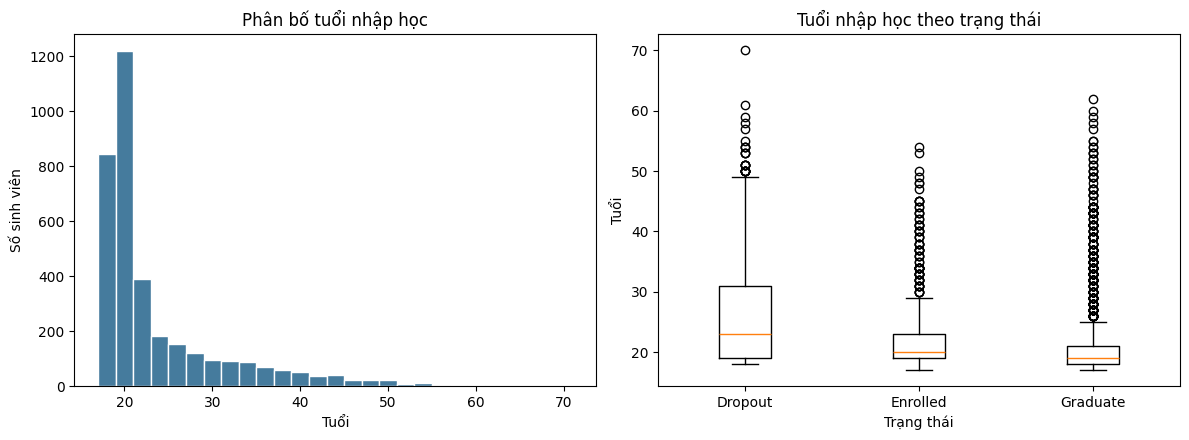

,count,mean,median,min,max
Target,,,,,
Dropout,1137,26.07,23.0,18,70
Enrolled,635,22.40,20.0,17,54
Graduate,1767,21.74,19.0,17,62


Đã lưu hình tại: c:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\report\figures\03_age_distribution.png


In [25]:
import matplotlib.pyplot as plt

class_order = ["Dropout", "Enrolled", "Graduate"]

figure_dir = project_dir / "report" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histogram tuổi nhập học
ages = development_df["Age at enrollment"]

axes[0].hist(
    ages,
    bins=range(int(ages.min()), int(ages.max()) + 3, 2),
    color="#457B9D",
    edgecolor="white"
)
axes[0].set_title("Phân bố tuổi nhập học")
axes[0].set_xlabel("Tuổi")
axes[0].set_ylabel("Số sinh viên")

# Boxplot tuổi theo từng lớp
age_groups = [
    development_df.loc[
        development_df["Target"] == label,
        "Age at enrollment"
    ].to_numpy()
    for label in class_order
]

axes[1].boxplot(age_groups)
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(class_order)
axes[1].set_title("Tuổi nhập học theo trạng thái")
axes[1].set_xlabel("Trạng thái")
axes[1].set_ylabel("Tuổi")

fig.tight_layout()

image_path = figure_dir / "03_age_distribution.png"
fig.savefig(image_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

# Bảng hỗ trợ nhận xét chính xác
display(
    development_df.groupby("Target")["Age at enrollment"]
    .agg(["count", "mean", "median", "min", "max"])
    .reindex(class_order)
    .round(2)
)

print("Đã lưu hình tại:", image_path)

### Nhận xét

- Phân bố tuổi nhập học lệch phải: phần lớn sinh viên tập trung
  ở độ tuổi trẻ, trong khi đuôi phân bố kéo dài đến 70 tuổi.
- Nhóm Dropout có tuổi trung bình 26,07 và trung vị 23,
  cao hơn nhóm Enrolled (22,40; trung vị 20) và
  Graduate (21,74; trung vị 19).
- Boxplot cho thấy tuổi của ba lớp vẫn chồng lấp.
  Vì vậy, riêng tuổi nhập học chưa đủ để phân biệt rõ ba trạng thái.
- Có các điểm tuổi cao nằm ngoài râu boxplot. Đây là những mẫu
  cần kiểm tra thêm, không mặc nhiên là dữ liệu sai.
- Giữ nguyên các bản ghi ở bước này.
- Kết quả mô tả mối liên hệ trong tập phát triển,
  không chứng minh tuổi cao gây ra tình trạng bỏ học.

## 7. Khám phá kết quả học tập theo trạng thái sinh viên

### Mục đích
Quan sát sự khác biệt về điểm và số học phần đạt giữa ba lớp
Dropout, Enrolled và Graduate.

### Cách thực hiện và lý do
- Vẽ boxplot của điểm và số học phần đạt trong hai học kỳ.
- So sánh trung vị, độ phân tán và mức độ chồng lấp giữa các lớp.
- Lập bảng trung vị để hỗ trợ nhận xét bằng số liệu.
- Chỉ sử dụng tập phát triển, chưa thay đổi dữ liệu.

### Phạm vi sử dụng
Các đặc trưng học kỳ 2 chỉ có thể dùng khi đã có kết quả học kỳ 2.
Thực nghiệm dùng các biến này không đại diện cho dự đoán ngay lúc nhập học.

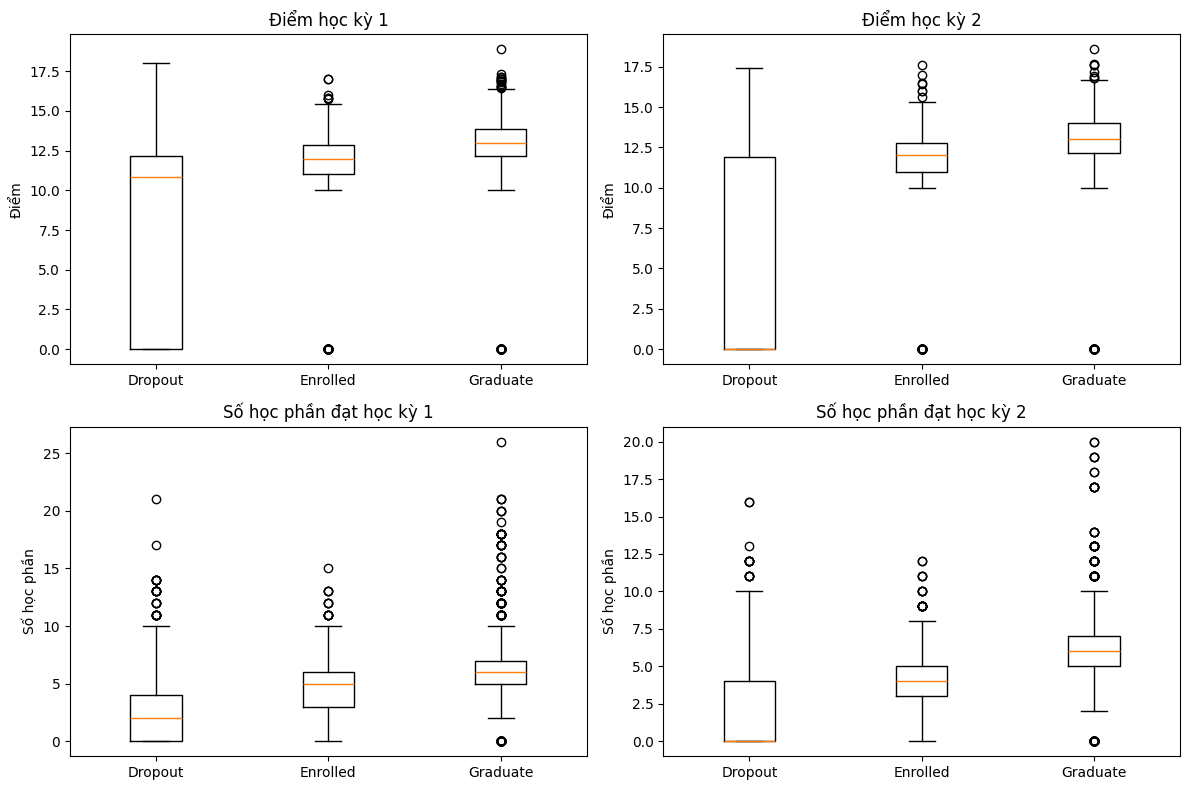

,Điểm học kỳ 1,Điểm học kỳ 2,Số học phần đạt học kỳ 1,Số học phần đạt học kỳ 2
Target,,,,
Dropout,10.83,0.0,2.0,0.0
Enrolled,12.00,12.0,5.0,4.0
Graduate,13.00,13.0,6.0,6.0


Đã lưu hình: c:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\report\figures\04_academic_by_target.png
Đã lưu bảng trung vị vào report/tables/04_academic_medians.csv


In [26]:
academic_features = {
    "Curricular units 1st sem (grade)": "Điểm học kỳ 1",
    "Curricular units 2nd sem (grade)": "Điểm học kỳ 2",
    "Curricular units 1st sem (approved)": "Số học phần đạt học kỳ 1",
    "Curricular units 2nd sem (approved)": "Số học phần đạt học kỳ 2"
}

class_order = ["Dropout", "Enrolled", "Graduate"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flat, academic_features.items()):
    groups = [
        development_df.loc[
            development_df["Target"] == label, column
        ].to_numpy()
        for label in class_order
    ]

    ax.boxplot(groups)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(class_order)
    ax.set_title(title)
    ax.set_ylabel("Điểm" if "(grade)" in column else "Số học phần")

fig.tight_layout()

figure_dir = project_dir / "report" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

image_path = figure_dir / "04_academic_by_target.png"
fig.savefig(image_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

# Bảng trung vị theo lớp
academic_medians = (
    development_df.groupby("Target")[list(academic_features)]
    .median()
    .reindex(class_order)
    .rename(columns=academic_features)
)

display(academic_medians.round(2))

table_dir = project_dir / "report" / "tables"
table_dir.mkdir(parents=True, exist_ok=True)

academic_medians.to_csv(
    table_dir / "04_academic_medians.csv",
    encoding="utf-8-sig",
    index_label="Target"
)

print("Đã lưu hình:", image_path)
print("Đã lưu bảng trung vị vào report/tables/04_academic_medians.csv")

### Nhận xét

- Graduate có trung vị điểm cao nhất: 13 ở cả hai học kỳ.
  Enrolled có trung vị 12 ở cả hai học kỳ.
- Dropout có trung vị điểm học kỳ 1 là 10,83,
  còn học kỳ 2 là 0.
- Trung vị số học phần đạt của Graduate là 6 ở cả hai học kỳ;
  Enrolled lần lượt là 5 và 4; Dropout lần lượt là 2 và 0.
- Các đặc trưng học tập có sự khác biệt giữa ba lớp,
  gợi ý khả năng hỗ trợ mô hình phân loại.
- Tuy nhiên, phân bố vẫn chồng lấp nên không thể dùng một
  ngưỡng điểm đơn giản để phân biệt hoàn toàn ba lớp.
- Trung vị điểm và số học phần đạt học kỳ 2 của Dropout bằng 0
  cần được kiểm tra thêm. Không tự động coi điểm 0 là missing,
  cũng chưa kết luận nguyên nhân từ biểu đồ.
- Giữ nguyên dữ liệu ở bước này. Giá trị dự đoán của các đặc trưng
  sẽ được kiểm chứng bằng thực nghiệm mô hình.
- Khi sử dụng thông tin học kỳ 2, phạm vi dự đoán phải được mô tả
  là sau khi có kết quả học kỳ 2, không phải ngay lúc nhập học.

## 8. Kiểm tra các trường hợp điểm học kỳ bằng 0

### Mục đích
Kiểm tra mối liên hệ giữa điểm bằng 0 và số học phần đạt
trong cùng học kỳ.

### Cách thực hiện và lý do
- Đếm các trường hợp điểm bằng 0 theo từng lớp.
- Tính tỷ lệ trong từng lớp vì ba lớp có số lượng khác nhau.
- Đối chiếu điểm bằng 0 với số học phần đạt bằng 0.
- Chỉ sử dụng tập phát triển.

Đây là bước kiểm tra tính nhất quán, chưa thay thế hoặc xóa giá trị.
Sự đồng xuất hiện không đủ để xác định nguyên nhân của điểm 0.

In [27]:
zero_summary_rows = []
consistency_rows = []

for semester in [1, 2]:
    grade_col = f"Curricular units {semester}st sem (grade)" if semester == 1 \
        else "Curricular units 2nd sem (grade)"
    approved_col = f"Curricular units {semester}st sem (approved)" if semester == 1 \
        else "Curricular units 2nd sem (approved)"

    # Đếm và tính tỷ lệ điểm 0 trong từng lớp
    for label in class_order:
        group = development_df[development_df["Target"] == label]
        zero_count = group[grade_col].eq(0).sum()

        zero_summary_rows.append({
            "Học kỳ": semester,
            "Target": label,
            "Số mẫu của lớp": len(group),
            "Số mẫu điểm 0": int(zero_count),
            "Tỷ lệ điểm 0 (%)": round(zero_count / len(group) * 100, 2)
        })

    # Đối chiếu điểm và số học phần đạt trên tập phát triển
    zero_grade = development_df[grade_col].eq(0)
    zero_approved = development_df[approved_col].eq(0)

    consistency_rows.append({
        "Học kỳ": semester,
        "Điểm 0, đạt 0": int((zero_grade & zero_approved).sum()),
        "Điểm 0, đạt > 0": int(
            (zero_grade & development_df[approved_col].gt(0)).sum()
        ),
        "Điểm > 0, đạt 0": int(
            (development_df[grade_col].gt(0) & zero_approved).sum()
        )
    })

zero_summary = pd.DataFrame(zero_summary_rows)
consistency_summary = pd.DataFrame(consistency_rows)

print("=== ĐIỂM 0 THEO TỪNG LỚP ===")
display(zero_summary)

print("=== ĐỐI CHIẾU ĐIỂM VÀ SỐ HỌC PHẦN ĐẠT ===")
display(consistency_summary)

table_dir = project_dir / "report" / "tables"
table_dir.mkdir(parents=True, exist_ok=True)

zero_summary.to_csv(
    table_dir / "05_zero_grade_by_target.csv",
    index=False,
    encoding="utf-8-sig"
)
consistency_summary.to_csv(
    table_dir / "05_zero_grade_consistency.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu hai bảng kiểm tra vào report/tables/")

=== ĐIỂM 0 THEO TỪNG LỚP ===


,Học kỳ,Target,Số mẫu của lớp,Số mẫu điểm 0,Tỷ lệ điểm 0 (%)
0,1,Dropout,1137,460,40.46
1,1,Enrolled,635,57,8.98
2,1,Graduate,1767,65,3.68
3,2,Dropout,1137,588,51.72
4,2,Enrolled,635,53,8.35
5,2,Graduate,1767,64,3.62


=== ĐỐI CHIẾU ĐIỂM VÀ SỐ HỌC PHẦN ĐẠT ===


,Học kỳ,"Điểm 0, đạt 0","Điểm 0, đạt > 0","Điểm > 0, đạt 0"
0,1,582,0,0
1,2,705,0,0


Đã lưu hai bảng kiểm tra vào report/tables/


### Nhận xét

- Học kỳ 1 có 582 mẫu vừa có điểm bằng 0 vừa có số học phần
  đạt bằng 0; học kỳ 2 có 705 mẫu.
- Trong cả hai học kỳ, không phát hiện trường hợp điểm bằng 0
  nhưng số học phần đạt lớn hơn 0, hoặc ngược lại.
- Tỷ lệ điểm 0 trong lớp Dropout cao hơn hai lớp còn lại:
  40,46% ở học kỳ 1 và 51,72% ở học kỳ 2.
- Tỷ lệ tương ứng của Enrolled là 8,98% và 8,35%;
  của Graduate là 3,68% và 3,62%.
- Điểm 0 cũng xuất hiện ở Enrolled và Graduate,
  vì vậy không thể coi điểm 0 đồng nghĩa với Dropout.
- Kết quả cho thấy sự nhất quán giữa hai trường trong tập phát triển,
  nhưng chưa xác định nguyên nhân hoặc quy ước tạo ra điểm 0.

### Quyết định tiền xử lý

- Giữ nguyên điểm 0 và các bản ghi liên quan trong thực nghiệm ban đầu.
- Không chuyển điểm 0 thành missing và không điền bằng trung bình.
- Tiếp tục đối chiếu tài liệu nguồn để làm rõ ý nghĩa của điểm học kỳ.
- Kiểm chứng giá trị dự đoán của các biến bằng cross-validation.

## 9. Phân nhóm đặc trưng và định hướng tiền xử lý

### Mục đích
Phân biệt biến danh mục, biến nhị phân và biến định lượng
để lựa chọn cách xử lý phù hợp.

### Cách thực hiện và lý do
- Biến danh mục: các số là mã nhóm, không biểu diễn độ lớn;
  dự kiến dùng One-Hot Encoding.
- Biến nhị phân: biểu diễn hai trạng thái 0/1;
  dự kiến giữ nguyên sau khi kiểm tra giá trị.
- Biến định lượng: biểu diễn số lượng, điểm, tuổi hoặc chỉ số kinh tế;
  dự kiến scaling khi dùng Logistic Regression và SVM.
- Decision Tree và Random Forest không cần scaling biến định lượng.

Chỉ xác định nhóm cột ở bước này. Encoder và scaler sẽ được fit
trong từng fold huấn luyện thông qua Pipeline để tránh data leakage.

In [28]:
# Làm sạch khoảng trắng và ký tự tab trong tên cột
# Không thay đổi giá trị dữ liệu
def clean_column_name(name):
    return " ".join(name.split())

# Phát hiện trường hợp làm sạch gây trùng tên
clean_names = [clean_column_name(c) for c in development_df.columns]
assert len(clean_names) == len(set(clean_names)), "Có tên cột bị trùng!"

# Dùng bản sao cho phần kiểm tra nhóm đặc trưng
schema_df = development_df.rename(columns=clean_column_name).copy()

categorical_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

binary_cols = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

numeric_cols = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
] + [
    f"Curricular units {semester} sem ({measure})"
    for semester in ["1st", "2nd"]
    for measure in [
        "credited",
        "enrolled",
        "evaluations",
        "approved",
        "grade",
        "without evaluations"
    ]
]

# Kiểm tra mỗi đặc trưng được phân nhóm đúng một lần
feature_cols = schema_df.drop(columns="Target").columns.tolist()
assigned_cols = categorical_cols + binary_cols + numeric_cols

assert len(assigned_cols) == len(set(assigned_cols)), "Phân nhóm bị trùng!"
assert set(assigned_cols) == set(feature_cols), (
    f"Chưa phân nhóm: {set(feature_cols) - set(assigned_cols)}\n"
    f"Không có trong dữ liệu: {set(assigned_cols) - set(feature_cols)}"
)

# Kiểm tra các cột nhị phân
for column in binary_cols:
    values = set(schema_df[column].dropna().unique())
    assert values <= {0, 1}, f"{column} có giá trị ngoài 0/1: {values}"

# Tạo bảng ghi nhận
feature_groups = pd.DataFrame([
    {
        "Feature": column,
        "Group": group,
        "Unique_values_in_development": schema_df[column].nunique()
    }
    for group, columns in [
        ("Categorical", categorical_cols),
        ("Binary", binary_cols),
        ("Numeric", numeric_cols)
    ]
    for column in columns
])

display(feature_groups)

print("Biến danh mục:", len(categorical_cols))
print("Biến nhị phân:", len(binary_cols))
print("Biến định lượng:", len(numeric_cols))
print("Tổng đặc trưng:", len(assigned_cols))

table_dir = project_dir / "report" / "tables"
table_dir.mkdir(parents=True, exist_ok=True)

feature_groups.to_csv(
    table_dir / "06_feature_groups.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu bảng phân nhóm vào report/tables/06_feature_groups.csv")

,Feature,Group,Unique_values_in_development
0,Marital status,Categorical,6
1,Application mode,Categorical,18
2,Course,Categorical,17
3,Previous qualification,Categorical,17
4,Nacionality,Categorical,19
5,Mother's qualification,Categorical,28
6,Father's qualification,Categorical,32
7,Mother's occupation,Categorical,31
8,Father's occupation,Categorical,41
9,Daytime/evening attendance,Binary,2


Biến danh mục: 9
Biến nhị phân: 8
Biến định lượng: 19
Tổng đặc trưng: 36
Đã lưu bảng phân nhóm vào report/tables/06_feature_groups.csv


### Nhận xét và quyết định tiền xử lý

- Đã phân nhóm đầy đủ 36 đặc trưng: 9 biến danh mục,
  8 biến nhị phân và 19 biến định lượng.
- Các biến danh mục có số giá trị khác nhau từ 6 đến 41.
  Dùng One-Hot Encoding để tránh coi mã danh mục là độ lớn.
- Encoder sẽ xử lý được danh mục chưa xuất hiện trong phần train
  bằng cấu hình handle_unknown="ignore".
- Các biến nhị phân được giữ nguyên dưới dạng 0/1.
- Các biến định lượng sẽ được chuẩn hóa bằng StandardScaler
  khi huấn luyện Logistic Regression và SVM.
- Decision Tree và Random Forest không cần scaling biến định lượng.
- Việc phân nhóm dựa trên ý nghĩa thuộc tính, không chỉ dựa vào
  kiểu dữ liệu hoặc số lượng giá trị khác nhau.
- Chưa fit encoder, scaler hoặc mô hình.
  Các bước này sẽ đặt trong Pipeline và fit trong từng fold train.

## 10. Tổng kết EDA và hướng thực nghiệm

### Kết quả đã đạt được
- Dữ liệu gồm 4.424 mẫu, 36 đặc trưng và biến mục tiêu Target.
- Không phát hiện giá trị thiếu bằng isna() hoặc dòng trùng hoàn toàn.
- Ba lớp có số lượng không đồng đều; Enrolled ít mẫu nhất.
- Đã chia 3.539 mẫu phát triển và 885 mẫu test, có stratification.
- Tuổi và các biến học tập có phân bố khác nhau giữa các lớp,
  nhưng vẫn có sự chồng lấp.
- Trong tập phát triển, điểm học kỳ bằng 0 luôn đi kèm
  số học phần đạt bằng 0.

### Quyết định cho thực nghiệm ban đầu
- Giữ nguyên các bản ghi và điểm 0; chưa loại ngoại lệ theo boxplot.
- One-hot 9 biến danh mục, giữ nguyên 8 biến nhị phân.
- Chuẩn hóa 19 biến định lượng cho Logistic Regression và SVM.
- Fit tiền xử lý trong từng fold bằng Pipeline.
- Dùng cùng dữ liệu và các fold CV để so sánh mô hình.
- Chọn Macro-F1 làm tiêu chí chính, theo dõi thêm Recall Dropout.
- Giữ riêng test, không dùng để chọn mô hình hoặc siêu tham số.

### Hạn chế
- EDA hiện tập trung vào tuổi và kết quả học tập,
  chưa phân tích sâu tất cả đặc trưng.
- Chưa xác minh đầy đủ mọi mã danh mục và giá trị bất thường.
- Chưa có kết quả huấn luyện để xác nhận giá trị dự đoán.
- Thực nghiệm dùng kết quả học kỳ 2 không đại diện cho
  dự đoán ngay lúc nhập học.

## Khảo sát B – Tỷ lệ học phần đạt HK1

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd


In [2]:
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

development_path = project_dir / "data" / "processed" / "development.csv"
eda_b = pd.read_csv(development_path)

enrolled = eda_b["Curricular units 1st sem (enrolled)"]
approved = eda_b["Curricular units 1st sem (approved)"]
labels = ["Dropout", "Enrolled", "Graduate"]


# Chỉ tính tỷ lệ khi sinh viên có đăng ký học phần.

,so_sinh_vien,dang_ky_0_mon,co_ty_le,trung_vi_ty_le_dat
Target,,,,
Dropout,1137,63,1074,0.4
Enrolled,635,21,614,0.8
Graduate,1767,64,1703,1.0


Tổng số sinh viên đăng ký 0 môn HK1: 148


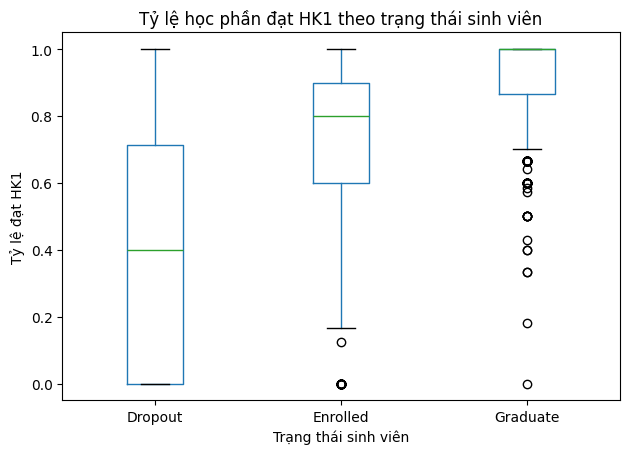

In [3]:
eda_b["hk1_pass_rate"] = approved.div(enrolled.where(enrolled > 0))
eda_b["hk1_zero_enrolled"] = enrolled.eq(0)

summary = eda_b.groupby("Target").agg(
    so_sinh_vien=("Target", "size"),
    dang_ky_0_mon=("hk1_zero_enrolled", "sum"),
    co_ty_le=("hk1_pass_rate", "count"),
    trung_vi_ty_le_dat=("hk1_pass_rate", "median"),
).reindex(labels)

display(summary)
print("Tổng số sinh viên đăng ký 0 môn HK1:", eda_b["hk1_zero_enrolled"].sum())

ax = eda_b.boxplot(column="hk1_pass_rate", by="Target", grid=False)
ax.set_title("Tỷ lệ học phần đạt HK1 theo trạng thái sinh viên")
ax.set_xlabel("Trạng thái sinh viên")
ax.set_ylabel("Tỷ lệ đạt HK1")
plt.suptitle("")
plt.tight_layout()
plt.show()